In [2]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

In [3]:
# Create file paths
root_fldr = Path.cwd().parent
fire25_path = root_fldr / "data" / "raw" / "fire25_1.shp"
rxburn25_path = root_fldr / "data" / "raw" / "rxburn25_1.shp"
fire_rxburn_25_path = root_fldr / "data" / "processed" / "fire_rxburn_25.csv"

fire_rxburn = pd.read_csv(fire_rxburn_25_path)

In [13]:
fire_rxburn.head()


,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,...,Shape_Leng,Shape_Area,GlobalID,rx_count,last_rx_date,rx_overlap_ha,rx_within_window,days_since_rx,fire_ha,rx_overlap_pct
0,2025,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025-08-01,2025-10-14,3,...,257388.320379,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},5,2024-01-17,3757.834684,True,562.0,53262.106218,7.055363
1,2025,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025-07-02,2025-07-26,7,...,191846.167384,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},1,2025-02-24,62.528239,True,128.0,32690.141169,0.191276
2,2025,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24,2025-10-23,3,...,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},59,2025-02-01,2220.287319,True,204.0,24288.922750,9.141152
3,2025,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02,2025-09-17,7,...,90080.360958,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},0,NaN,0.000000,False,NaN,10341.153237,0.000000
4,2025,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07,2025-01-31,7,...,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},2,1988-06-08,73.864810,True,13362.0,9489.426413,0.778391


In [33]:
fire_rxburn['ALARM_DATE'] = pd.to_datetime(fire_rxburn['ALARM_DATE'], format = '%Y-%m-%d')
fire_rxburn['CONT_DATE'] = pd.to_datetime(fire_rxburn['CONT_DATE'], format = '%Y-%m-%d')

fire_rxburn['duration'] = fire_rxburn['CONT_DATE'] - fire_rxburn['ALARM_DATE']
#fire_rxburn = fire_rxburn.astype({'duration':int})
fire_rxburn.head()

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,...,Shape_Area,GlobalID,rx_count,last_rx_date,rx_overlap_ha,rx_within_window,days_since_rx,fire_ha,rx_overlap_pct,duration
0,2025,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025-08-01,2025-10-14,3,...,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},5,2024-01-17,3757.834684,True,562.0,53262.106218,7.055363,74 days
1,2025,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025-07-02,2025-07-26,7,...,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},1,2025-02-24,62.528239,True,128.0,32690.141169,0.191276,24 days
2,2025,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24,2025-10-23,3,...,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},59,2025-02-01,2220.287319,True,204.0,24288.922750,9.141152,60 days
3,2025,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02,2025-09-17,7,...,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},0,NaN,0.000000,False,NaN,10341.153237,0.000000,15 days
4,2025,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07,2025-01-31,7,...,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},2,1988-06-08,73.864810,True,13362.0,9489.426413,0.778391,24 days


In [36]:
rx_summary = (fire_rxburn.groupby(['rx_within_window']).agg(
    count=('rx_within_window', 'count'),
    mean_acres = ('GIS_ACRES', 'mean'),
    mean_duration = ('duration', 'mean')
))

rx_summary['mean_duration'] = rx_summary['mean_duration'].dt.days
rx_summary.head()

,count,mean_acres,mean_duration
rx_within_window,,,
False,9210,710.261662,6
True,14124,2698.534775,13


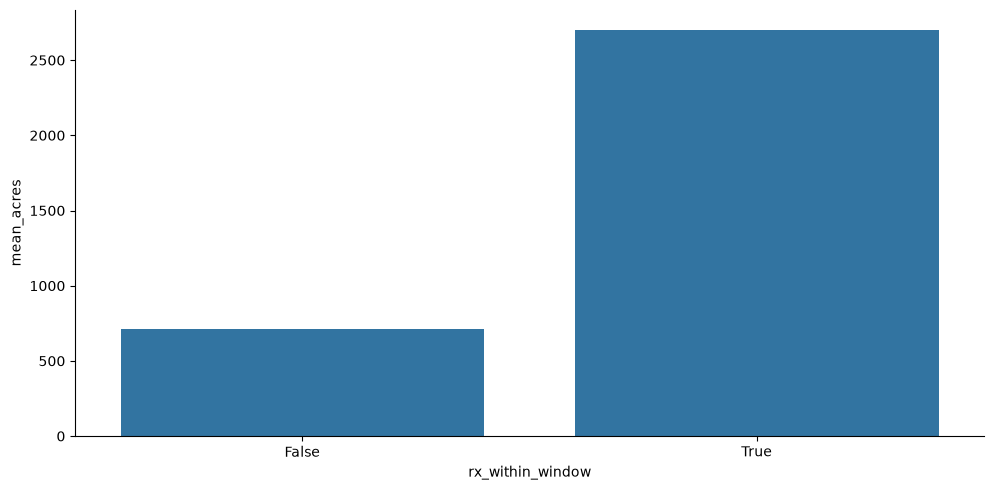

In [30]:
g = sns.catplot(
            data=rx_summary,
            x='rx_within_window',
            y='mean_acres',
            kind='bar',
            aspect=2
            )

In [ ]:


fire_rxburn.info()


<class 'pandas.DataFrame'>
RangeIndex: 23334 entries, 0 to 23333
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   YEAR_             23334 non-null  int64         
 1   STATE             23334 non-null  str           
 2   AGENCY            23286 non-null  str           
 3   UNIT_ID           23274 non-null  str           
 4   FIRE_NAME         16679 non-null  str           
 5   INC_NUM           22379 non-null  str           
 6   IRWINID           3633 non-null   str           
 7   ALARM_DATE        17950 non-null  datetime64[us]
 8   CONT_DATE         10716 non-null  datetime64[us]
 9   C_METHOD          23334 non-null  int64         
 10  CAUSE             23334 non-null  int64         
 11  OBJECTIVE         23334 non-null  int64         
 12  GIS_ACRES         23334 non-null  float64       
 13  COMPLEX_ID        584 non-null    str           
 14  COMPLEX_NA        618 non-null   

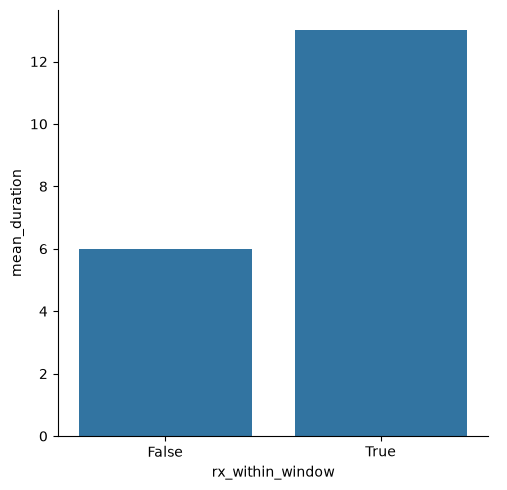

In [37]:
g = sns.catplot(
            data=rx_summary,
            x='rx_within_window',
            y='mean_duration',
            kind='bar'
            )